Housing Price Dataset: Exploratory Data Analysis

Objective:
Understand the structure and quality of the housing data, study the regression target 'house_sale_price', explore how each feature relates to price (alone and in combination), and draw out what this means for the modelling stage.

Notebook structure
1. Dataset overview and data quality
2. Target variable analysis
3. Univariate feature analysis (numerical, then categorical)
4. Correlation analysis
5. Interaction analysis
6. Key findings and modelling implications


1. Dataset Overview

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# Load dataset
df = pd.read_csv("Housing_Price_Dataset.csv")

df.head()

,property_size,number_of_bedrooms,number_of_bathrooms,location_type,age_of_property,proximity_to_public_transport,crime_rate_in_area,school_quality_score,house_sale_price
0,3008.37,-0.346,-0.2740,Suburban,0.0474,19.890,0.03920,8.71,449268.00
1,3270.77,0.307,0.5650,Rural,0.2450,2.600,0.00271,9.36,553784.29
2,1810.05,-0.144,-0.0214,Suburban,0.1790,5.360,0.08630,6.24,277421.86
3,5171.61,1.410,0.6860,Urban,0.2560,0.401,0.01100,9.35,459590.56
4,3195.10,0.541,0.8490,Suburban,0.3550,2.730,0.02340,6.54,333659.33


In [31]:
# Number of rows and columns
df.shape

(1000, 9)

The dataset has 1,000 observations and 9 colums: 8 predictors and 1 target (house_sale_price). For a tabular regression problem with only 8 features, 1,000 rows is a reasonable sample for exploration and for classical models (linear regression, regularised models, trees ensembles). It is on the small side for very flexible models, so cross-validation will matter more than a single train/test split.

In [32]:
# Column names
df.columns.to_list()

['property_size',
 'number_of_bedrooms',
 'number_of_bathrooms',
 'location_type',
 'age_of_property',
 'proximity_to_public_transport',
 'crime_rate_in_area',
 'school_quality_score',
 'house_sale_price']

In [33]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   property_size                  1000 non-null   float64
 1   number_of_bedrooms             1000 non-null   float64
 2   number_of_bathrooms            1000 non-null   float64
 3   location_type                  1000 non-null   str    
 4   age_of_property                1000 non-null   float64
 5   proximity_to_public_transport  1000 non-null   float64
 6   crime_rate_in_area             1000 non-null   float64
 7   school_quality_score           1000 non-null   float64
 8   house_sale_price               1000 non-null   float64
dtypes: float64(8), str(1)
memory usage: 70.4 KB


All 8 predictors besides location_type are float, and location_type is the only text column. Every column has 1,000 non-null entries, so there are no missing values in the raw data.

In [34]:
# Descriptive statistics (numerical columns)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
property_size,1000.0,2647.638830,1294.745544,779.700000,1754.30750,2417.490000,3134.80250,11345.780
number_of_bedrooms,1000.0,0.046277,1.007127,-2.630000,-0.65425,0.061900,0.70225,3.850
number_of_bathrooms,1000.0,0.011666,0.985091,-2.810000,-0.63025,0.000135,0.66100,3.090
age_of_property,1000.0,0.352023,0.188704,0.028600,0.21300,0.314000,0.45500,1.210
proximity_to_public_transport,1000.0,9.901814,9.162502,0.136000,2.99750,7.120000,14.16500,62.320
crime_rate_in_area,1000.0,0.074814,0.088008,0.000005,0.01440,0.046600,0.10300,0.719
school_quality_score,1000.0,7.069930,1.633160,1.830000,5.91750,7.285000,8.37000,9.910
house_sale_price,1000.0,350137.916310,130904.595271,120520.430000,262227.04250,323881.575000,405511.94000,1202878.270


In [35]:
# Summary statistics for all columns, including categorical ones
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
property_size,1000.0,NaN,NaN,NaN,2647.63883,1294.745544,779.7,1754.3075,2417.49,3134.8025,11345.78
number_of_bedrooms,1000.0,NaN,NaN,NaN,0.046277,1.007127,-2.63,-0.65425,0.0619,0.70225,3.85
number_of_bathrooms,1000.0,NaN,NaN,NaN,0.011666,0.985091,-2.81,-0.63025,0.000135,0.661,3.09
location_type,1000,3,Suburban,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_of_property,1000.0,NaN,NaN,NaN,0.352023,0.188704,0.0286,0.213,0.314,0.455,1.21
proximity_to_public_transport,1000.0,NaN,NaN,NaN,9.901814,9.162502,0.136,2.9975,7.12,14.165,62.32
crime_rate_in_area,1000.0,NaN,NaN,NaN,0.074814,0.088008,0.000005,0.0144,0.0466,0.103,0.719
school_quality_score,1000.0,NaN,NaN,NaN,7.06993,1.63316,1.83,5.9175,7.285,8.37,9.91
house_sale_price,1000.0,NaN,NaN,NaN,350137.91631,130904.595271,120520.43,262227.0425,323881.575,405511.94,1202878.27


Observations from the summary statistics
- number_of_bedrooms and number_of_bathrooms are not raw counts. Both have mean near 0 and a standard deviation near 1, with negative minimums (about -2.6 and -2.8). They look like standardised (z-scored) values, so a "bedroom" value of -0.35 cannot be read literally. They should be interpreted as relative size (above or below average), and no rounding or "fixing" of the negatives is appropriate. 
- property_size is right-skewed: the median is about 2,417 but the maximum is about 11,346, roughly 4.7 times the median.
- crime_rate_in_area is strongly right_skewed: median about 0.047, maximum about 0.719. Most areas are low-crime with a few high-crime ones.
- proximity_to_public transport also has a long right tail (median about 7.1, maximum about 62.3)
- house_sale_price ranges from about 120,520 to 1,202,878 with a mean (about 350,138) above the median (about 323,882) a first sign of right skew.

Verifying that bedrooms and bathrooms are standardised 

The summary statistics suggested that number_of_bedrooms and number_of_bathrooms are z-scores rather than counts. If that is right, their mean should be about 0 and their standard deviation about 1, overall and (if the scaling was applied to the whole dataset) approximately within each location group too. 

In [36]:
zcols = ['number_of_bedrooms', 'number_of_bathrooms']

overall = df[zcols].agg(['mean', 'std']).T.round(3)
print("Overall:")
print(overall)
print()
print("By location_type:")
print(df.groupby('location_type')[zcols].agg(['mean', 'std']).round(3))
print()
for c in zcols:
    w, p = stats.shapiro(df[c])
    print(f"{c}: min = {df[c].min():.2f}, max = {df[c].max():.2f}, share below 0 = {(df[c] < 0).mean():.1%}, Shapiro-Wilk p = {p:.3f}")

Overall:
                      mean    std
number_of_bedrooms   0.046  1.007
number_of_bathrooms  0.012  0.985

By location_type:
              number_of_bedrooms        number_of_bathrooms       
                            mean    std                mean    std
location_type                                                     
Rural                      0.039  1.144              -0.087  1.000
Suburban                   0.053  0.968               0.076  0.956
Urban                      0.040  1.022              -0.044  1.013

number_of_bedrooms: min = -2.63, max = 3.85, share below 0 = 47.9%, Shapiro-Wilk p = 0.077
number_of_bathrooms: min = -2.81, max = 3.09, share below 0 = 50.0%, Shapiro-Wilk p = 0.687


Confirmed. Overall the means are 0.046 and 0.012 and the standard deviations 1.007 and 0.985, which is what z-scoring produces. Close to half of the bedrooms values (47.9%) are below zero, which is impossible for a real room count. Within the location groups the means stay near 0 (between about -0.09 and 0.08) and the standard deviations between 0.96 and 1.14 (the largest 1.14, is Rural bedrooms, based on only 100 rows). This pattern means the scaling was applied once to the whole dataset, not separately within each location, so the group legitimately differ slightly. The Shapiro-wilk test does not reject normality fir either column (p=0.077 and p=0.69), consistent with standardised, roughly normal variables.

Consequence: treat these two features as relative size (above or below average). Do not round, clip or "fix" the negative values, and do not rescale them again for linear or distance-based models, since they are already on a z-scale. The other features are on very different scales and will need scaling for those models.

In [37]:
# Check missing values
df.isnull().sum()

property_size                    0
number_of_bedrooms               0
number_of_bathrooms              0
location_type                    0
age_of_property                  0
proximity_to_public_transport    0
crime_rate_in_area               0
school_quality_score             0
house_sale_price                 0
dtype: int64

In [38]:
# Identify duplicates
df.duplicated().sum()

np.int64(0)

Data quality. There are 0 missing values and 0 duplicated rows, so no imputation or de-duplication is needed. the remaining data-quality questions are about outliers and skewness, which are examined below.


In [39]:
# Identify numerical and categorical features
target = 'house_sale_price'

numerical_features = df.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_features = df.select_dtypes(include=["object","string","category","bool"]).columns.tolist()

# Predictors only (target excluded) for the feature-level plots
num_predictors = [c for c in numerical_features if c != target]

print("Numerical features :", numerical_features)
print("Categorical features:", categorical_features)
print("Numerical predictors: ", num_predictors)

Numerical features : ['property_size', 'number_of_bedrooms', 'number_of_bathrooms', 'age_of_property', 'proximity_to_public_transport', 'crime_rate_in_area', 'school_quality_score', 'house_sale_price']
Categorical features: ['location_type']
Numerical predictors:  ['property_size', 'number_of_bedrooms', 'number_of_bathrooms', 'age_of_property', 'proximity_to_public_transport', 'crime_rate_in_area', 'school_quality_score']


In [40]:
# Category sizes (checks whether any subgroup is too small for reliable comparison)
counts = df['location_type'].value_counts()
pd.DataFrame({'counts':counts, 'share_%': (counts / len(df) * 100).round(1)})

,counts,share_%
location_type,,
Suburban,500,50.0
Urban,400,40.0
Rural,100,10.0


Subgroup size. location_type has three levels: Suburban (500, 50%), Urban (400, 40%) and Rural (only 100, 10%). Comparisons that involve Rural are less stable than the others because the sample is five times smaller than Suburban. Rural-specific patterns later in this notebook should be treated as indicative rather than conclusive.

2. Target Variable Analysis:
house_sale_price

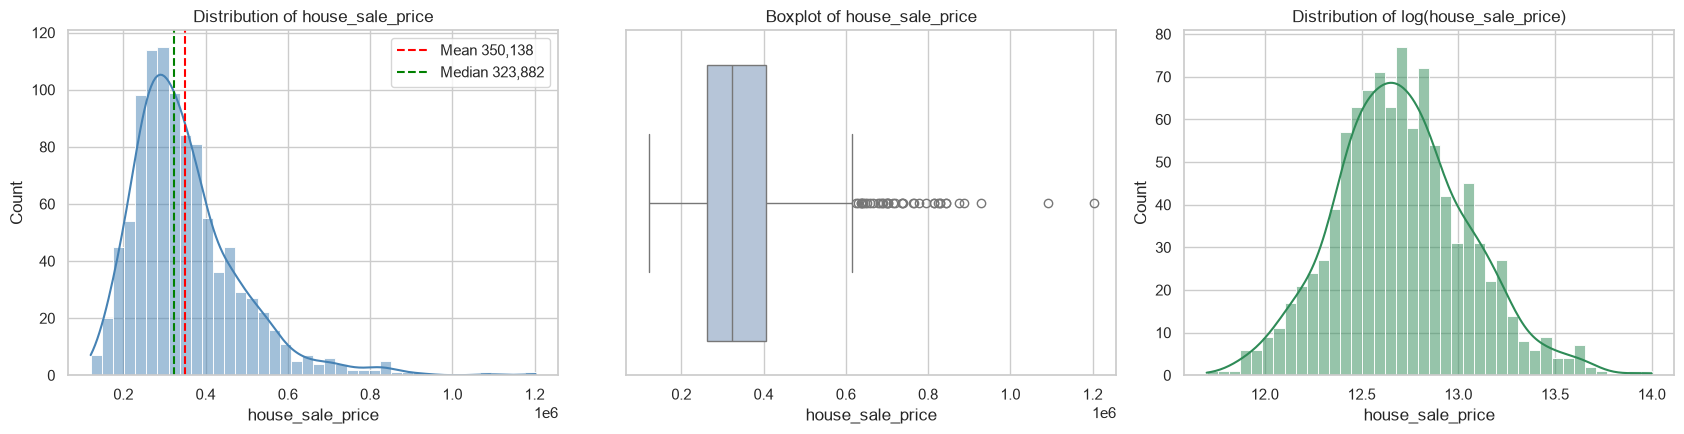

In [41]:
y = df[target]

fig, axes = plt.subplots(1,3, figsize=(17, 4.5))

sns.histplot(y, kde=True, bins=40, ax=axes[0], color="steelblue")
axes[0].axvline(y.mean(), color="red", ls="--", label=f"Mean {y.mean():,.0f}")
axes[0].axvline(y.median(), color="green", ls="--", label=f"Median {y.median():,.0f}")
axes[0].set_title("Distribution of house_sale_price")
axes[0].legend()

sns.boxplot(x=y, ax=axes[1], color="lightsteelblue")
axes[1].set_title("Boxplot of house_sale_price")

sns.histplot(np.log(y), kde=True, bins=40, ax=axes[2], color="seagreen")
axes[2].set_title("Distribution of log(house_sale_price)")
plt.tight_layout()

In [42]:
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
n_out = (y > upper_fence).sum()

print(f"Skewness (raw target)      : {y.skew():.3f}")
print(f"Skewness (log target)      : {np.log(y).skew():.3f}")
print(f"Mean / Median              : {y.mean():,.0f} / {y.median():,.0f}")
print(f"IQR upper fence            : {upper_fence:,.0f}")
print(f"Outliers above fence       : {n_out} ({n_out/len(y)*100:.1f}%)")
print(f"Max / Median               : {y.max()/y.median():.2f}x")
print()
print(y.describe(percentiles=[.01, .25, .5, .75, .9, .99]).round(0))


Skewness (raw target)      : 1.574
Skewness (log target)      : 0.274
Mean / Median              : 350,138 / 323,882
IQR upper fence            : 620,439
Outliers above fence       : 39 (3.9%)
Max / Median               : 3.71x

count       1000.0
mean      350138.0
std       130905.0
min       120520.0
1%        155774.0
25%       262227.0
50%       323882.0
75%       405512.0
90%       517503.0
99%       814353.0
max      1202878.0
Name: house_sale_price, dtype: float64


What the target looks like
- The distribution is right-skewed (skewness about 1.57). The mean (about 350k) sits above (about 324k), and a long tail of expensive homes stretches out to about 1.2 million.
- The boxplot flags 39 properties (3.9%) above the upper IQR fence of about 620k. The most expensive home is about 3.7 times the median price, so these look like genuine high-value homes rather than mistakes. I would keep them.
- After a log transform the skewness drops to about 0.27, so the distribution becomes much more symmetric.

Modelling implications
- Because the tail is long, large errors on expensive houses will dominate RMSE (it squares errors). It is worth reporting MAE (or median absolute error) next to RMSE, and possibly MAPE/RMSlE so that a 50k error on a 1 M house is judged differently from a 50k error on a 150k house.
- A log-transformed target should be tested, particularly for linear models, where it should help with residual spread and the influence of the high-price tail. Predictions would then be back-transformed with np.exp.
- Tree-based models are not sensitive to target skew in the same way, but the metric choice above still applies

2.1 Is a transformation justified? Q-Q plots and Box-Cox

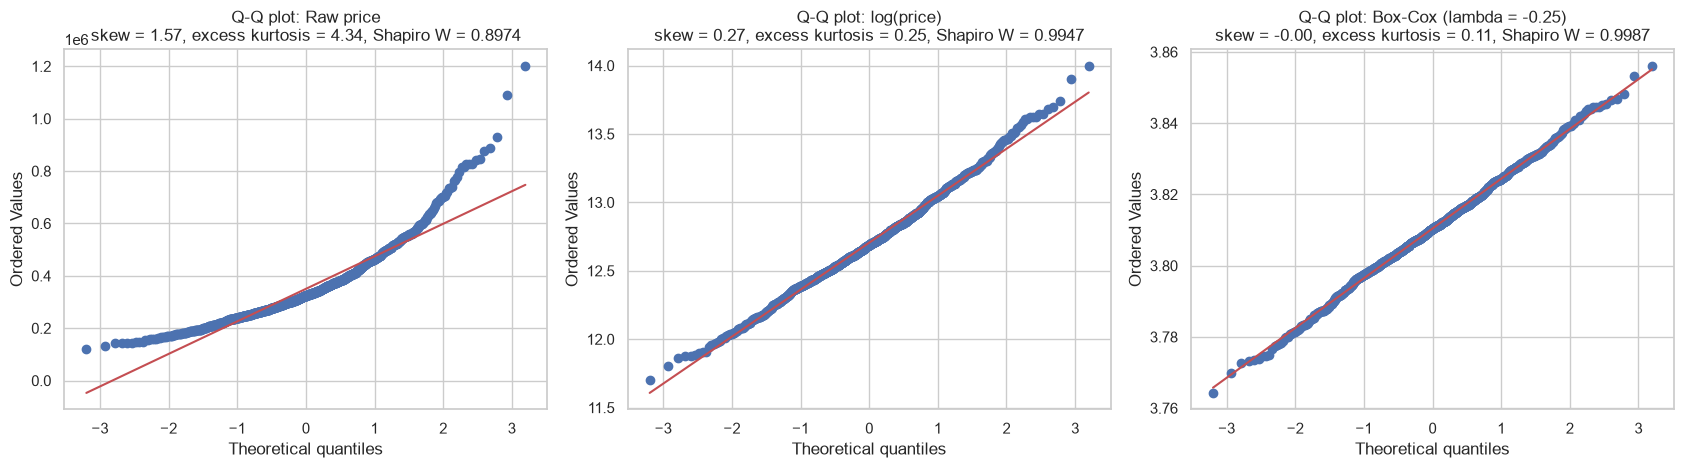

In [45]:
y_bc, lam = stats.boxcox(y)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (data, name) in zip(axes, [(y, 'Raw price'),
                                    (np.log(y), 'log(price)'),
                                    (y_bc, f'Box-Cox (lambda = {lam:.2f})')]):
    stats.probplot(data, dist='norm', plot=ax)
    w, p = stats.shapiro(data)
    ax.set_title(f"Q-Q plot: {name}\nskew = {stats.skew(data):.2f}, excess kurtosis = {stats.kurtosis(data):.2f}, Shapiro W = {w:.4f}")
plt.tight_layout()
plt.show()

- Raw price: the Q-Q plot bends sharply away from the reference line in the upper tail (the largest prices are far higher than a normal distribution would give), with excess kurtosis of about 4.3 and Shapiro-wilk W of about 0.897. The departure is clearly in the right tail, not just a few stray points.
- log(price): the points sit very close to the line (skew about 0.27, excess kurtosis about 0.25, W about 0.995), with n = 1,000 the Shapiro-Wilk test still rejects exact normality (p about 0.001), but it flags tiny deviations at this sample size, so the Q-Q plot and the skew/kurtosis values matter more here: the log transform removes nearly all the tail problem.
- Box-Cox: the fitted lambda is about -0.25, close to 0 ( which would be the pure log). Box-Cox gets slightly closer to normal (skew about 0.00, W about 0.9987), but log is sensible, easily back-transformed choice.

Modelling implications: test the log target first (simple back-transform with np.exp), and keep Box-Cox (lambda about -0.25) as an alternative to compare. Normality of the target is not itself a requirement for linear regression; what matters is the behaviour

3. Univariate Feature Analysis

3.1 Numerical features: distributions

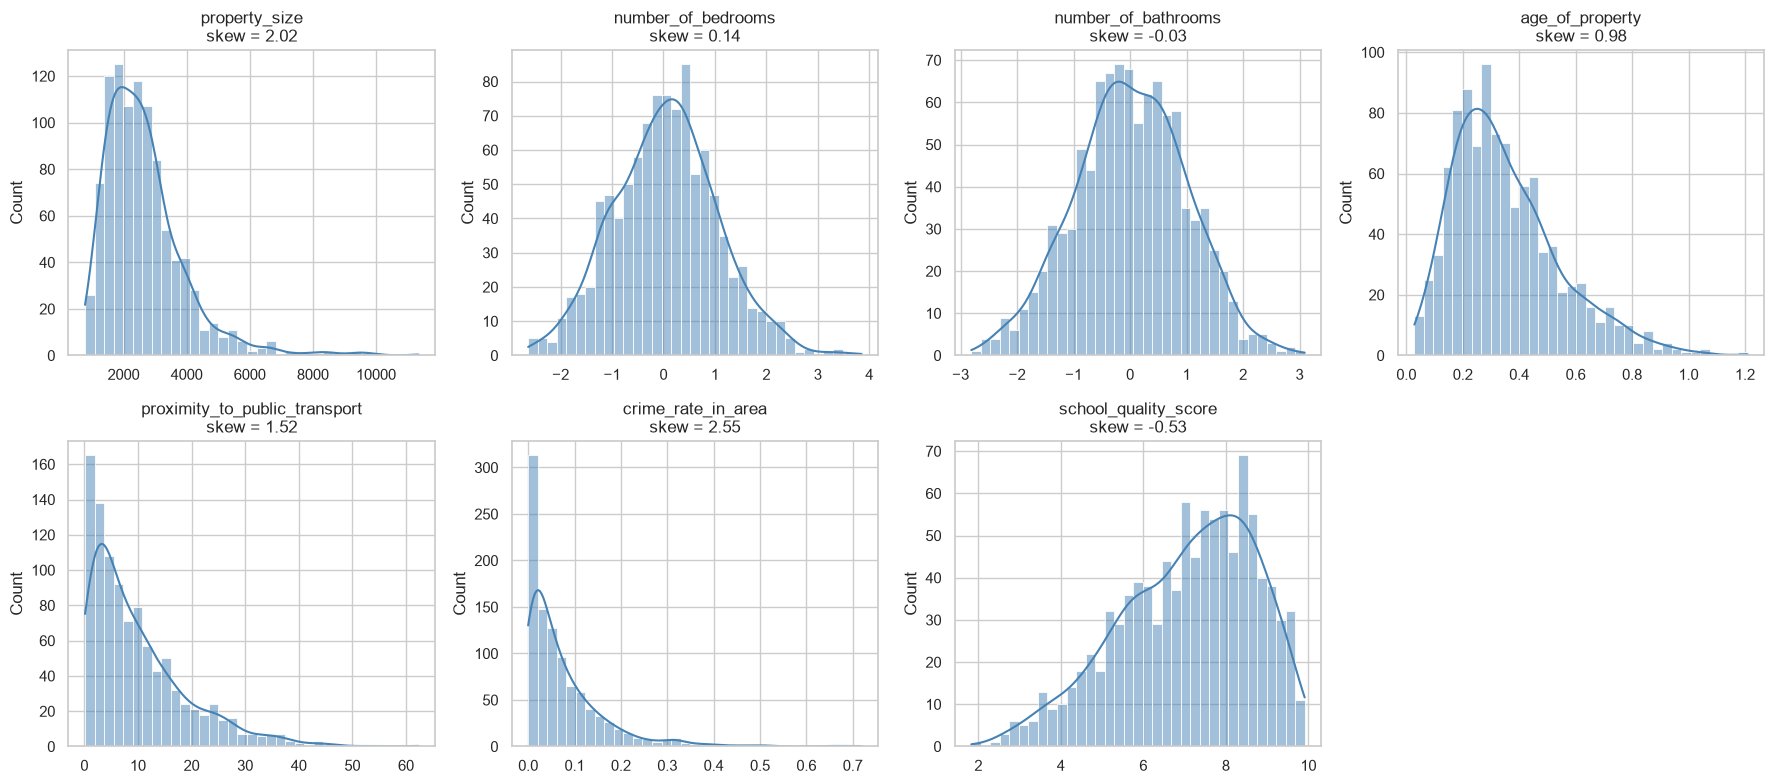

In [43]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_predictors):
    sns.histplot(df[col], kde=True, bins=35, ax=ax, color="steelblue")
    ax.set_title(f"{col}\nskew = {df[col].skew():.2f}")
    ax.set_xlabel("")
# one spare panel: hide it
for ax in axes.ravel()[len(num_predictors):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [44]:
def iqr_outliers(s):
    a, b = s.quantile([.25, .75]); i = b - a
    return int(((s < a - 1.5*i) | (s > b + 1.5*i)).sum())

summary = pd.DataFrame({
    'skew': df[num_predictors].skew().round(2),
    'IQR outliers': df[num_predictors].apply(iqr_outliers),
}).sort_values('skew', ascending=False)
summary

,skew,IQR outliers
crime_rate_in_area,2.55,54
property_size,2.02,46
proximity_to_public_transport,1.52,38
age_of_property,0.98,23
number_of_bedrooms,0.14,6
number_of_bathrooms,-0.03,7
school_quality_score,-0.53,1


Distribution observations
- Strongly right-skewed: crime_rate_in_area (skew about 2.55, 54 IQR outliers), property_size (about 2.02, 46 outliers), proximity_to_public_transport (about 1,52, 38 outliers) and, more moderately, age_of_property (about 0.98).
- Roughly symmetric: number_of_bedrooms (about 0.14) and number_of_bathrooms (about -0.03). This fits with them being standardised values.
school_quality_score is mildly left_skewed (about -0,53): most areas have good schools, with a thin tail of low scores (its scale tops out around 9.9).

Linear and distance-based models may benefit from log or Box-Cox style transforms of the heavily skewed predictors (crime_rate_in_area, property_size, proximity_to_public_transport). Tree-based models do not need this.

3.2 Numerical features vs. house_sale_price

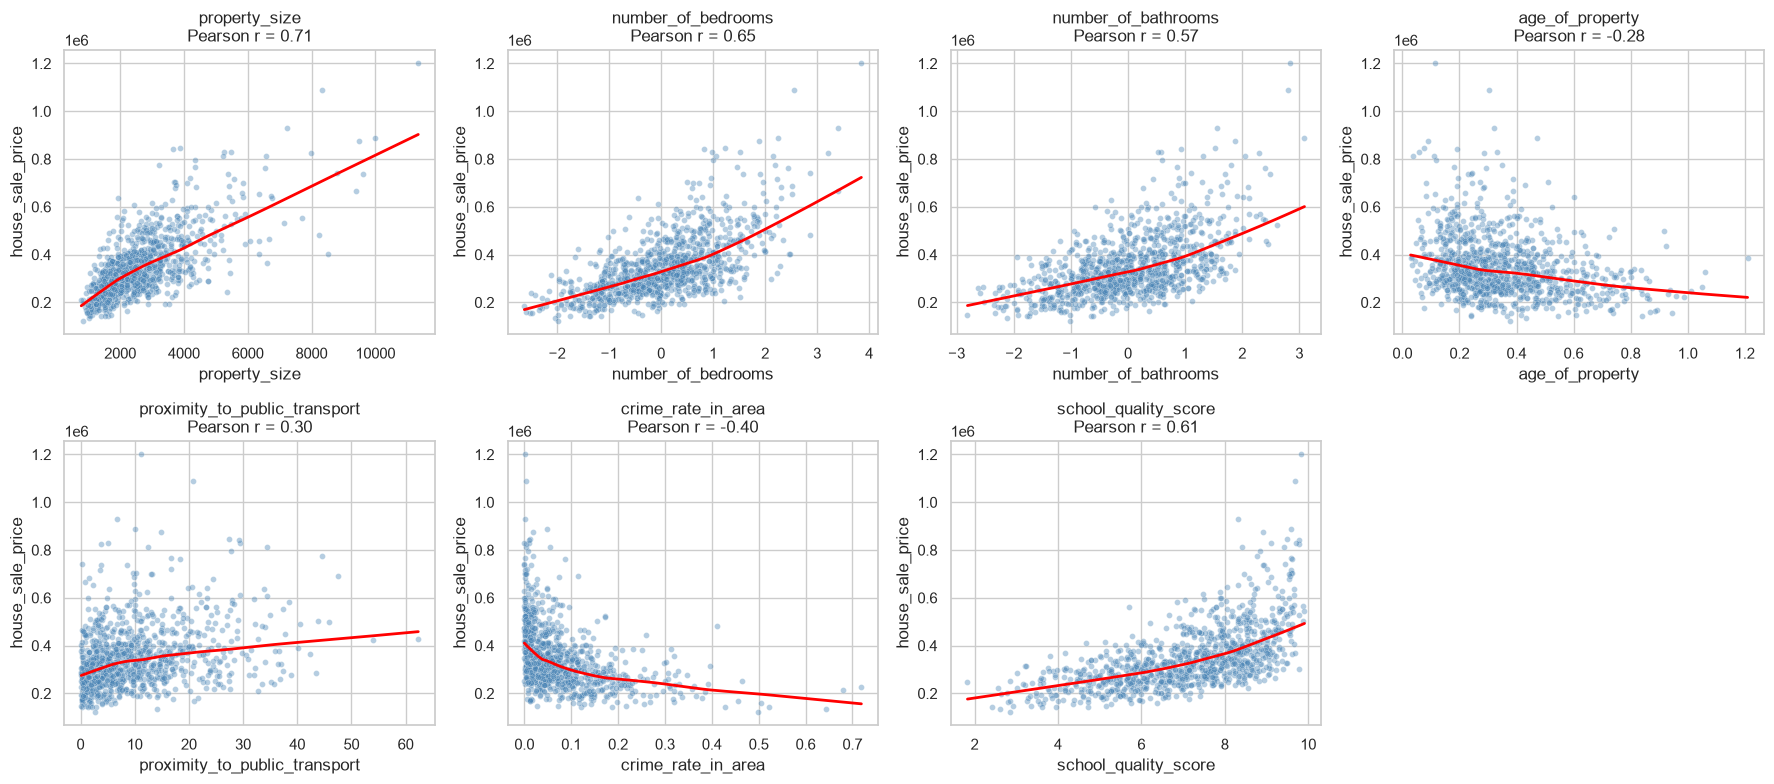

In [15]:

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_predictors):
    sns.scatterplot(data=df, x=col, y=target, alpha=0.4, s=18, ax=ax, color="steelblue")
    sns.regplot(data=df, x=col, y=target, scatter=False, lowess=True,
                line_kws={"color": "red", "lw": 2}, ax=ax)
    r = df[col].corr(df[target])
    ax.set_title(f"{col}\nPearson r = {r:.2f}")
for ax in axes.ravel()[len(num_predictors):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Relationship with price
- Property_size (r about 0.71) is the strongest single relationship: bigger homes sell for more, and the increase looks broadly linear but with a widening spread at larger sizes (heteroscedasticity), which is another argument for testing a log target.
- school_quality_score (r about 0.61) has a clear positive relationship.
- number_of_bedrooms (r about 0.65) and number_of_bathrooms (r about 0.57) are positively related to price, but they are also correlated with property size, so part of their signal is shared.
- crime_rate_int_area (r about -0.40) has a negative relationship. The lOWESS curve is steepest at low crime rates, so the price penalty is strongest as crime first rises from very low levels and flattens afterwards, i.e. it is not a straight line.
- Proximity_to_public_transport (r about 0.30) is mildly positive. Since this variable is a distance-style measure (the long right tail suggest larger values mean farther away), I would not assume the direction is intuitive. A positive correlation here is surprising and may be confounded by location type; the dataset has no data dictionary, so this should be confirmed with the data owner.
- age_of_property (r about -0.28) shows a mild negative relationship: older properties tend to be cheaper.


3.3 Does a log transform of crime_rate_in_area linearise its relationship with price?

Smallest crime value: 4.72e-06 (> 0, so the log needs no shift)


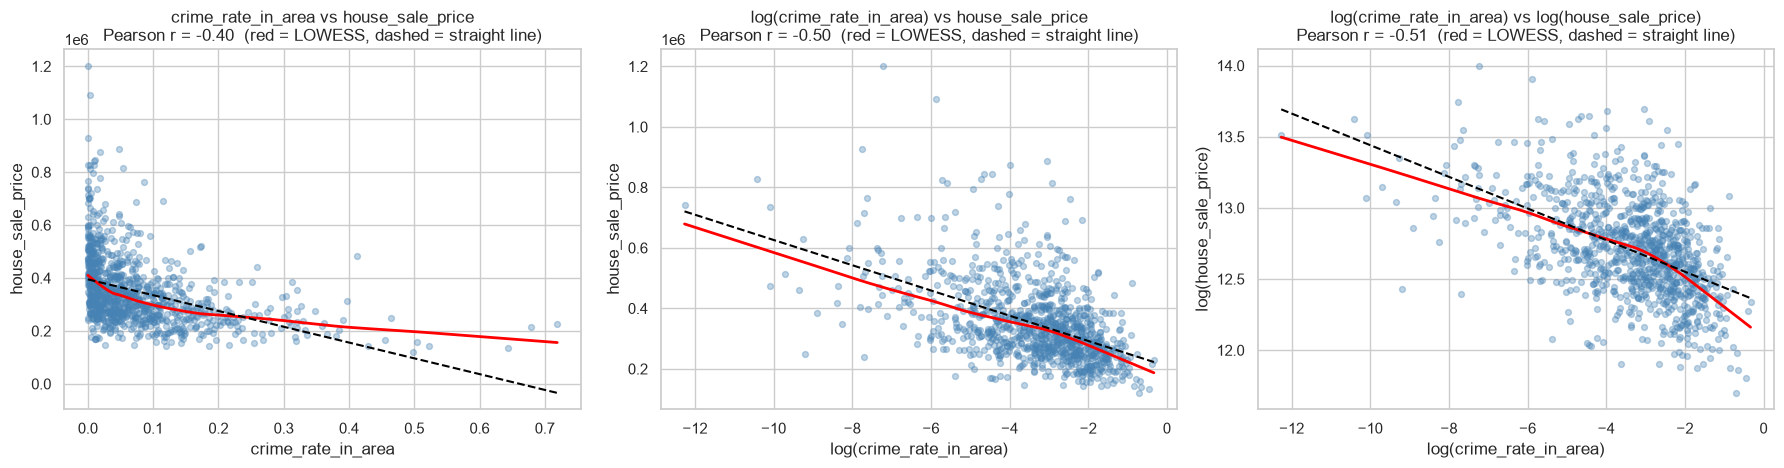

In [46]:
crime = df['crime_rate_in_area']
print("Smallest crime value:", crime.min(), "(> 0, so the log needs no shift)")

df['_log_crime'] = np.log(crime)
panels = [
    (crime, df[target], 'crime_rate_in_area', 'house_sale_price'),
    (df['_log_crime'], df[target], 'log(crime_rate_in_area)', 'house_sale_price'),
    (df['_log_crime'], np.log(df[target]), 'log(crime_rate_in_area)', 'log(house_sale_price)'),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (xv, yv, xl, yl) in zip(axes, panels):
    ax.scatter(xv, yv, alpha=0.35, s=18, color='steelblue')
    sns.regplot(x=xv, y=yv, scatter=False, lowess=True, line_kws={'color': 'red', 'lw': 2}, ax=ax)               # flexible trend
    sns.regplot(x=xv, y=yv, scatter=False, ci=None, line_kws={'color': 'black', 'ls': '--', 'lw': 1.5}, ax=ax)  # straight line
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.set_title(f"{xl} vs {yl}\nPearson r = {xv.corr(yv):.2f}  (red = LOWESS, dashed = straight line)")
plt.tight_layout()
plt.show()

In [47]:
rows = []
for xname, x in [('raw', crime), ('log', np.log(crime)), ('sqrt', np.sqrt(crime))]:
    for yname, yy in [('price', df[target]), ('log(price)', np.log(df[target]))]:
        lin = sm.OLS(yy, sm.add_constant(x)).fit()
        quad = sm.OLS(yy, sm.add_constant(pd.DataFrame({'x': x, 'x2': x ** 2}))).fit()
        rows.append({'crime version': xname, 'target': yname, 'skew of crime version': round(x.skew(), 2),
                     'Pearson r': round(x.corr(yy), 3), 'Spearman rho': round(x.corr(yy, method='spearman'), 3),
                     'linear R2': round(lin.rsquared, 3), 'R2 with squared term': round(quad.rsquared, 3),
                     'p-value of squared term': round(quad.pvalues['x2'], 4)})
df.drop(columns='_log_crime', inplace=True)
pd.DataFrame(rows)

,crime version,target,skew of crime version,Pearson r,Spearman rho,linear R2,R2 with squared term,p-value of squared term
0,raw,price,2.55,-0.401,-0.509,0.161,0.198,0.0000
1,raw,log(price),2.55,-0.461,-0.509,0.213,0.243,0.0000
2,log,price,-1.26,-0.504,-0.509,0.254,0.256,0.1178
3,log,log(price),-1.26,-0.512,-0.509,0.262,0.274,0.0000
4,sqrt,price,0.82,-0.472,-0.509,0.223,0.241,0.0000
5,sqrt,log(price),0.82,-0.515,-0.509,0.266,0.271,0.0048


Yes, the log transforms helps a lot.
- Against raw price, the Pearson correlation improves from -0.40 (raw crime) to -0.50 (log crime) and the straight-line R-squared from 0.161 to 0.254. The log version (-0.50) now almost matches the Spearman rank correlation (-0.51), which is the ceiling for any monotonic relationship, so the transform recovers essentially all of the monotonic signal that the raw Pearson value was missing.
- The red LOWESS curve and the dashed straight line agree much more closely after the transform. Stastically, a squared tearm is clearly significant for raw crime (p<0.001) but not for log crime against price (p about 0.12), meaning the curvature has been removed.
- Against log(price) a little curvature remains (squared term p<0.001), but it adds little (R-squared 0.262 to 0.274).
- Caveat: log crime is now left-skewed (skew about -1.26), because the many very small crime value are stretched out. The square toot is a milder alternative (R-squared 0.223 against price), but the log performs best here.

Modelling implication: use log(crime_rate_in_area) as the crime feature for linear and regularised models. Tree-based models are unaffected by monotonic transformations of a feature, so there is nothing to change for them.

3.4 Categorical feature: location-type

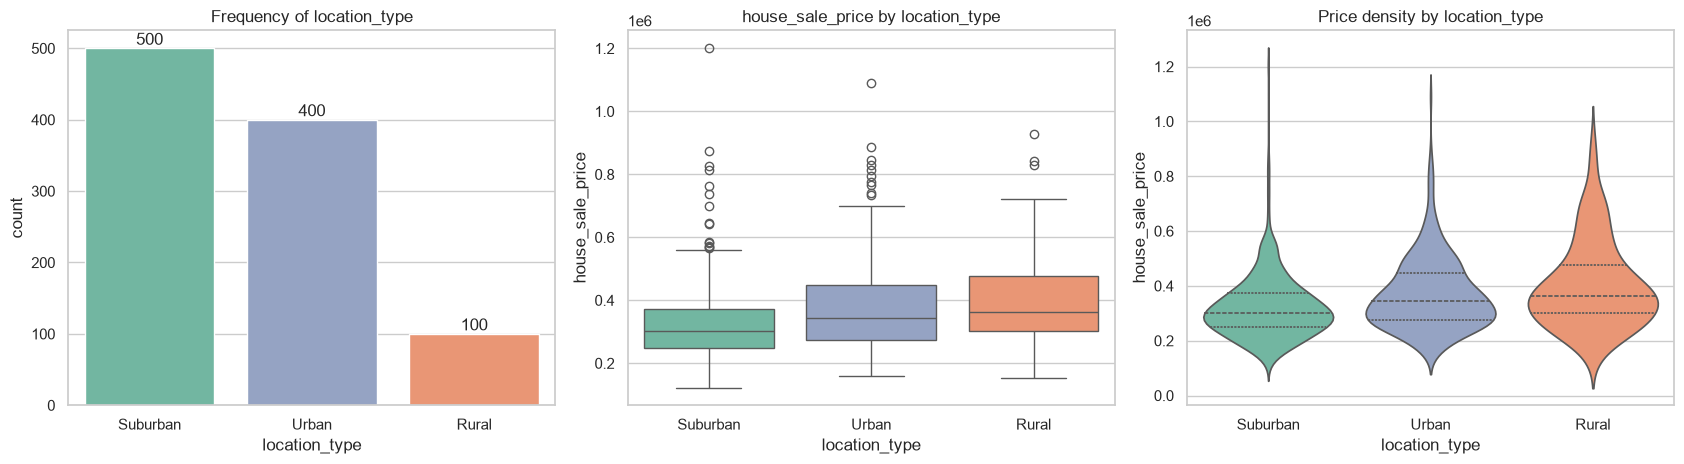

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

order = df['location_type'].value_counts().index
sns.countplot(data=df, x='location_type', order=order, ax=axes[0], palette="Set2", hue='location_type', legend=False)
axes[0].set_title("Frequency of location_type")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom')

sns.boxplot(data=df, x='location_type', y=target, order=order, ax=axes[1], palette="Set2", hue='location_type', legend=False)
axes[1].set_title("house_sale_price by location_type")

sns.violinplot(data=df, x='location_type', y=target, order=order, ax=axes[2], palette="Set2", hue='location_type', legend=False, inner="quartile")
axes[2].set_title("Price density by location_type")

plt.tight_layout()
plt.show()

In [17]:
df.groupby('location_type')[target].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(0)


,count,mean,median,std,min,max
location_type,,,,,,
Rural,100,404179.0,362868.0,159617.0,153711.0,928413.0
Suburban,500,322589.0,300833.0,115594.0,120520.0,1202878.0
Urban,400,371063.0,343212.0,133229.0,158260.0,1090647.0


In [18]:
df.groupby('location_type')[num_predictors].mean().round(2).T

location_type,Rural,Suburban,Urban
property_size,2458.82,2721.68,2602.29
number_of_bedrooms,0.04,0.05,0.04
number_of_bathrooms,-0.09,0.08,-0.04
age_of_property,0.53,0.30,0.38
proximity_to_public_transport,9.54,9.67,10.28
crime_rate_in_area,0.04,0.10,0.06
school_quality_score,7.80,6.77,7.26


Location observations
- Rural homes are the most expensive on average (mean about 404k, median about 363k), followed by Urban (about 371k mean) and Suburban (about 323k mean, about 301k median). This is not the ordering most people would guess.
- The group profiles help explain it: Rural areas have the lowest crime (mean about 0.04 vs 0.10 in Suburban) and the highest school scores (about 7.80 vs 6.77 in Suburban), and Rural homes also tend to be the oldest (mean age about 0.53 vs 0.30 for Suburban; again the scale of this feature is unclear). Suburban areas have the highest crime and the lowest school scores, which lines up with their lowest prices. 
- Rural also has the widest price spread (std about 160k vs about 116k for suburban), but with only 100 rows these estimates are the least reliable.
- All three group overlap heavily, so location_type alone is a weak separator of price. it is probably more useful together with the other features.

Modelling implication. 
location_type has only three unordered levels, so one-hot encoding is the natural choice ( no ordinal meaning should be implied). Since Rural is small group, I would use stratified splitting/ stratified cross-validation on location_type so every fold contains enough Rural rows.

3.5 Are the price differences between location statistically reliable?


In [49]:
from itertools import combinations

groups = {loc: d[target].values for loc, d in df.groupby('location_type')}
k, n = len(groups), len(df)

H, p_kw = stats.kruskal(*groups.values())
eps2 = (H - k + 1) / (n - k)                      # epsilon-squared effect size for Kruskal-Wallis
lev_w, p_lev = stats.levene(*groups.values())
print(f"Kruskal-Wallis: H = {H:.2f}, p = {p_kw:.2e}, epsilon^2 = {eps2:.3f}")
print(f"Levene test for equal variances: W = {lev_w:.2f}, p = {p_lev:.4f}")
print()

pairs = list(combinations(groups, 2))
rows = []
for a, b in pairs:
    U, p = stats.mannwhitneyu(groups[a], groups[b], alternative='two-sided')
    delta = 2 * U / (len(groups[a]) * len(groups[b])) - 1      # Cliff's delta, positive = first group tends to be higher
    rows.append({'comparison': f"{a} vs {b}", 'p-value (Bonferroni)': min(p * len(pairs), 1.0),
                 "Cliff's delta": round(delta, 3)})
pd.DataFrame(rows).set_index('comparison')

Kruskal-Wallis: H = 47.85, p = 4.06e-11, epsilon^2 = 0.046
Levene test for equal variances: W = 9.03, p = 0.0001



,p-value (Bonferroni),Cliff's delta
comparison,,
Rural vs Suburban,1.211615e-06,0.321
Rural vs Urban,3.166961e-01,0.105
Suburban vs Urban,1.223701e-08,-0.228


- **Kruskal-Wallis:** H of about 47.9 with p of about 4e-11, so the price distributions are **not the same across the three location types**. This does not depend on the skewed prices or unequal group sizes, since it works on ranks. The Levene test (p about 0.0001) also shows that the spread of prices differs between groups, which is another reason to prefer a rank-based test here.
- **Effect size:** epsilon-squared is only about 0.046, so location type explains a **small share** of the variation in price. It is statistically clear but practically modest, which fits the heavy overlap seen in the boxplots.
- **Post-hoc (Mann-Whitney, Bonferroni-adjusted):**
  - **Suburban vs Rural:** significant (adjusted p about 1e-6); Rural tends to be higher (Cliff's delta about +0.32, a small-to-medium effect).
  - **Suburban vs Urban:** significant (adjusted p about 1e-8); Suburban tends to be lower (delta about -0.23, small).
  - **Rural vs Urban:** **not significant** (adjusted p about 0.32; delta about 0.11, negligible). Even though Rural's average price is higher, the difference from Urban could easily be sampling noise given only 100 Rural rows.

**So the reliable finding is that Suburban homes are cheaper than both other groups, not that Rural homes are the most expensive.** This sharpens the earlier reading: Rural and Urban should not be described as different in price on this evidence.


## 4. Correlation Analysis

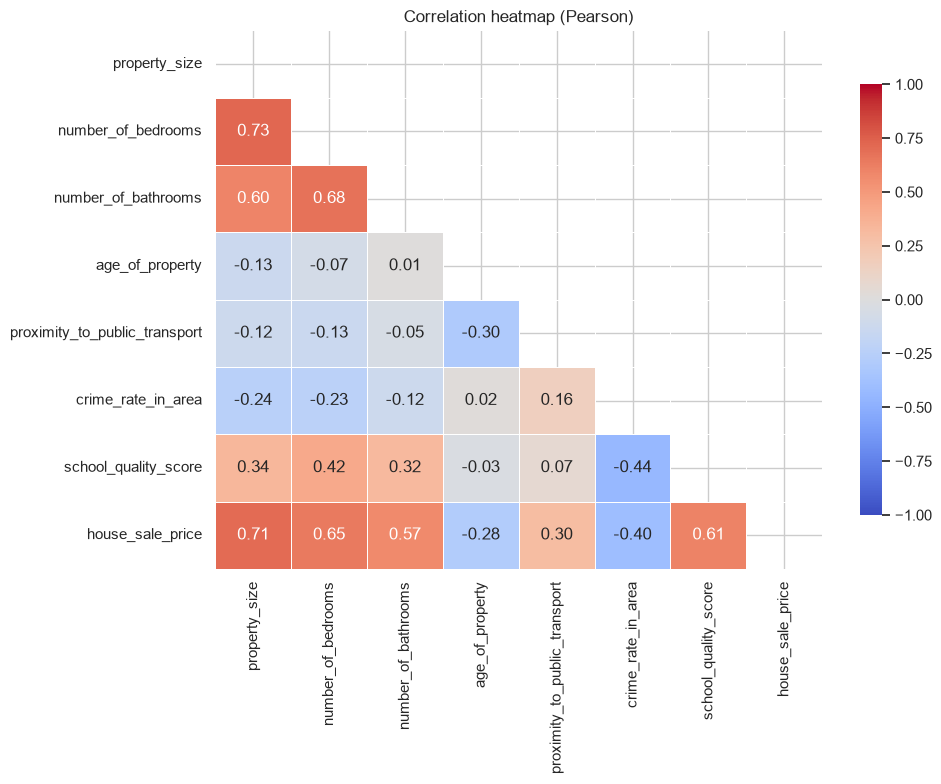

In [21]:
corr = df[numerical_features].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10,8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Correlation heatmap (Pearson)")
plt.tight_layout()
plt.show()

In [22]:
# Correlation with the target, ranked by strength (Pearson and Spearman)
ranked = pd.DataFrame({
    'pearson': df[num_predictors].corrwith(df[target]),
    'spearman': df[num_predictors].corrwith(df[target], method='spearman'),
}).round(2)
ranked = ranked.reindex(ranked['pearson'].abs().sort_values(ascending=False).index)
ranked


,pearson,spearman
property_size,0.71,0.67
number_of_bedrooms,0.65,0.64
school_quality_score,0.61,0.65
number_of_bathrooms,0.57,0.55
crime_rate_in_area,-0.40,-0.51
proximity_to_public_transport,0.30,0.32
age_of_property,-0.28,-0.30


In [23]:
# Strongest predictor-vs-predictor correlations (multicollinearity check)
pairs = (corr.loc[num_predictors, num_predictors]
         .where(np.triu(np.ones((len(num_predictors),)*2, dtype=bool), k=1))
         .stack().rename('corr').reset_index())
pairs.columns = ['feature_1', 'feature_2', 'corr']
pairs.reindex(pairs['corr'].abs().sort_values(ascending=False).index).head(6).round(2)

,feature_1,feature_2,corr
1,property_size,number_of_bedrooms,0.73
9,number_of_bedrooms,number_of_bathrooms,0.68
2,property_size,number_of_bathrooms,0.60
41,crime_rate_in_area,school_quality_score,-0.44
13,number_of_bedrooms,school_quality_score,0.42
6,property_size,school_quality_score,0.34


Correlation findings
- Most related to price: Property_size (0.71), number_of_bedrooms (0.65), school_quality_score (0.61), number_of_bathrooms (0.57). Then crime_rate_in_area (-0.40), proximity_to_public_transport (0.30) and age_of_property (-0.28). The Spearman (rank) correlation are broadly similar for most features, so these relationships are not just driven by outliers. The exception is crime_rate_in_area, whose Spearman correlation (-0.51) is noticeably stronger than its Pearson one (-0.40): the relationship is monotonic but curved, so a straight-line correlation understates it.
- Multicollinearity among predictors: the size-related features move together: property_size-number_of_bedrooms (0.73), number_of_bedrooms-number_of_bathrooms (0.68), property_size-number_of_bathrooms (0.60), school_quality_score and crime_rate_in_area are also moderately related (-0.44): safer areas tend to have better schools.
- None of the predictor pairs is above 0.8, so there is no extreme redundancy, but coefficients in a plain linear regression may be unstable and harder to interpret for the size group (checking VIF would be a good next step). Ridge/Lasso or tree-based models handle this better.
- Correlation only measures linear association. It says nothing about causation and can hide the non-linear crime effect noticed above.



4.1 Quantifying multicollinearity with VIF

In [51]:
from statsmodels.stats.outliers_influence import variance_inflation_factor 

def vif_table(X):
    X = sm.add_constant(X.astype(float))
    return pd.Series({c: variance_inflation_factor(X.values, i) for i, c in enumerate(X.columns) if c != 'const'}).round(2)

vif_num = vif_table(df[num_predictors]).rename('VIF (numeric predictors)')
vif_all = vif_table(pd.get_dummies(df[num_predictors + ['location_type']], drop_first=True)).rename('VIF (with location dummies)')
pd.concat([vif_num, vif_all], axis=1).sort_values('VIF (with location dummies)', ascending=False)

,VIF (numeric predictors),VIF (with location dummies)
location_type_Suburban,NaN,3.84
location_type_Urban,NaN,3.27
number_of_bedrooms,2.80,2.81
property_size,2.31,2.31
number_of_bathrooms,2.00,2.03
school_quality_score,1.52,1.54
age_of_property,1.16,1.41
crime_rate_in_area,1.33,1.40
proximity_to_public_transport,1.23,1.26


Multicollinearity is mild. The largest VIF among the numerical predictors is about 2.8 (`number_of_bedrooms`), followed by `property_size` (about 2.3) and `number_of_bathrooms` (about 2.0); all other predictors are below 1.6. Every value is below the common warning level of 5 (and far below the looser 10). Adding the location dummies barely changes this (the highest is about 3.8, for the Suburban dummy, which reflects its overlap with crime, school and age patterns).

The pairwise correlations among the size features (0.60 to 0.73) therefore look more worrying than they are: the three variables share information, but not enough to make coeeficient estimates unstable. A plain linear regression is acceptable, and Ridge/Lasso is a reasonable option for tuning and generalisation rather than a necessity for fixing collinearity. It is still sensible to check coefficient stability across cross-validation folds, particularly for bedrooms and size.

# 5. Interaction Analysis
## 5.1 Property size vs. Price, by location type

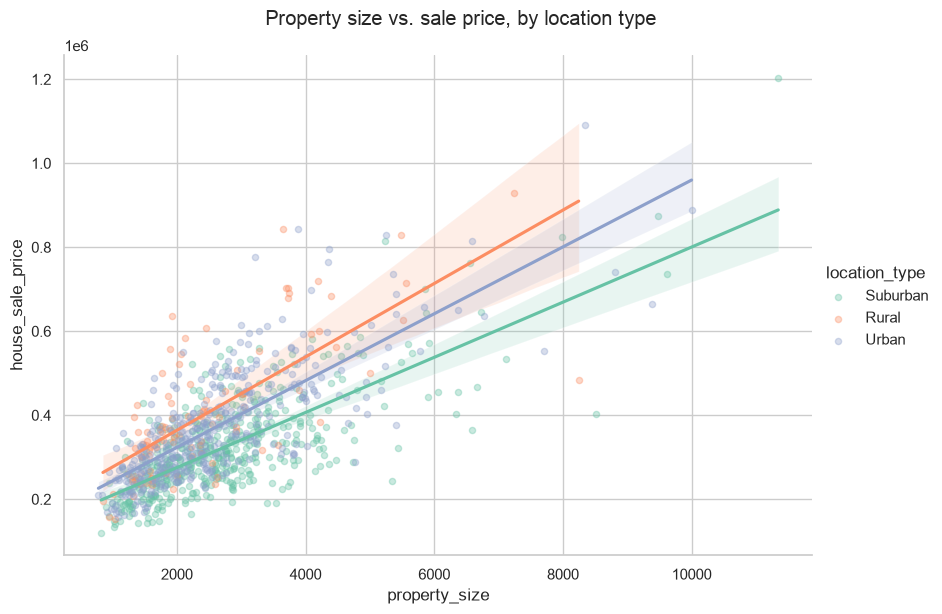

,slope (price per size unit),intercept,r
location_type,,,
Rural,87.4,189303,0.72
Suburban,65.7,143902,0.74
Urban,79.6,163895,0.77


In [24]:
g = sns.lmplot(data=df, x='property_size', y=target, hue='location_type',
               height=6, aspect=1.4, scatter_kws={'alpha': 0.35, 's': 20}, palette="Set2")
g.fig.suptitle("Property size vs. sale price, by location type", y=1.02)
plt.show()

# Slope (price change per unit of size) and within-group correlation
rows = []
for loc, d in df.groupby('location_type'):
    slope, intercept = np.polyfit(d['property_size'], d[target], 1)
    rows.append({'location_type': loc, 'slope (price per size unit)': round(slope, 1),
                 'intercept': round(intercept), 'r': round(d['property_size'].corr(d[target]), 2)})
pd.DataFrame(rows).set_index('location_type')


Within each location the relationship is strongly linear (r between 0.72 and 0.77). the fitted slopes are broadly similar, about 87 per unit of size in Rural, 80 in Urban and 66 in Suburban, an the lines are close to parallel but sit at different heights (Rural highest, Suburban lowest). So location mostly shifts the price level, and there is only a mild size x location interaction. Rural has the steepest slope, but with onlt 100 rows i would not read much into the difference.

Modelling implication: an additive model with one-hot location_type captures most of this. An sxplicit property_size * location_type interaction term could be testes in linear model but is unlikely to give a big gain


## 5.2 Crime rate vs. price, by location type

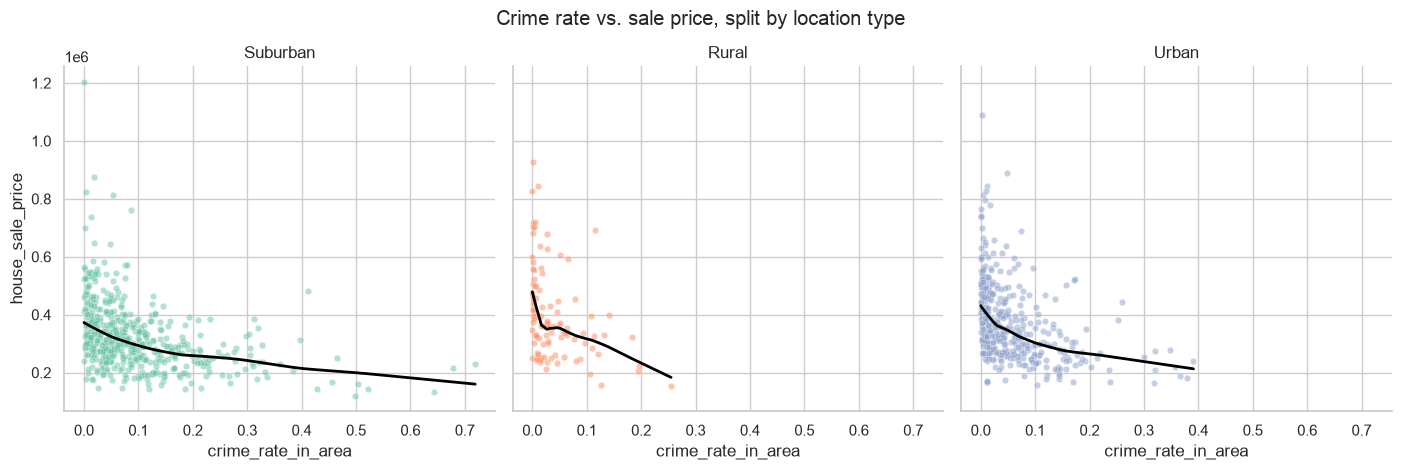

location_type
Rural      -0.39
Suburban   -0.38
Urban      -0.40
Name: r (crime vs price), dtype: float64

In [25]:
g = sns.FacetGrid(df, col='location_type', hue='location_type', height=4.5, aspect=1.05, palette="Set2")
g.map_dataframe(sns.scatterplot, x='crime_rate_in_area', y=target, alpha=0.5, s=22)
g.map_dataframe(sns.regplot, x='crime_rate_in_area', y=target, scatter=False, lowess=True,
                line_kws={'color': 'black', 'lw': 2})
g.set_titles("{col_name}")
g.fig.suptitle("Crime rate vs. sale price, split by location type", y=1.04)
plt.show()

df.groupby('location_type')['crime_rate_in_area'].apply(lambda s: s.corr(df.loc[s.index, target])).round(2).rename('r (crime vs price)')

The crime-price relationship is negative in every location type with very similar strength (r about -0.38 to -0.40)/ I do not see evidence that crime hurts prices more in one subgroup than another. the differences between locations come from the different crime levels in each ( Suburban is the highest, Rural the lowest), not from a different effect of crime. Because the crime distribution is skewed and the relatinship is curved, a log transform of crime (or tree-based model) ,ay fit better than a straight line.

## 5.3 School quality and crime rate together 

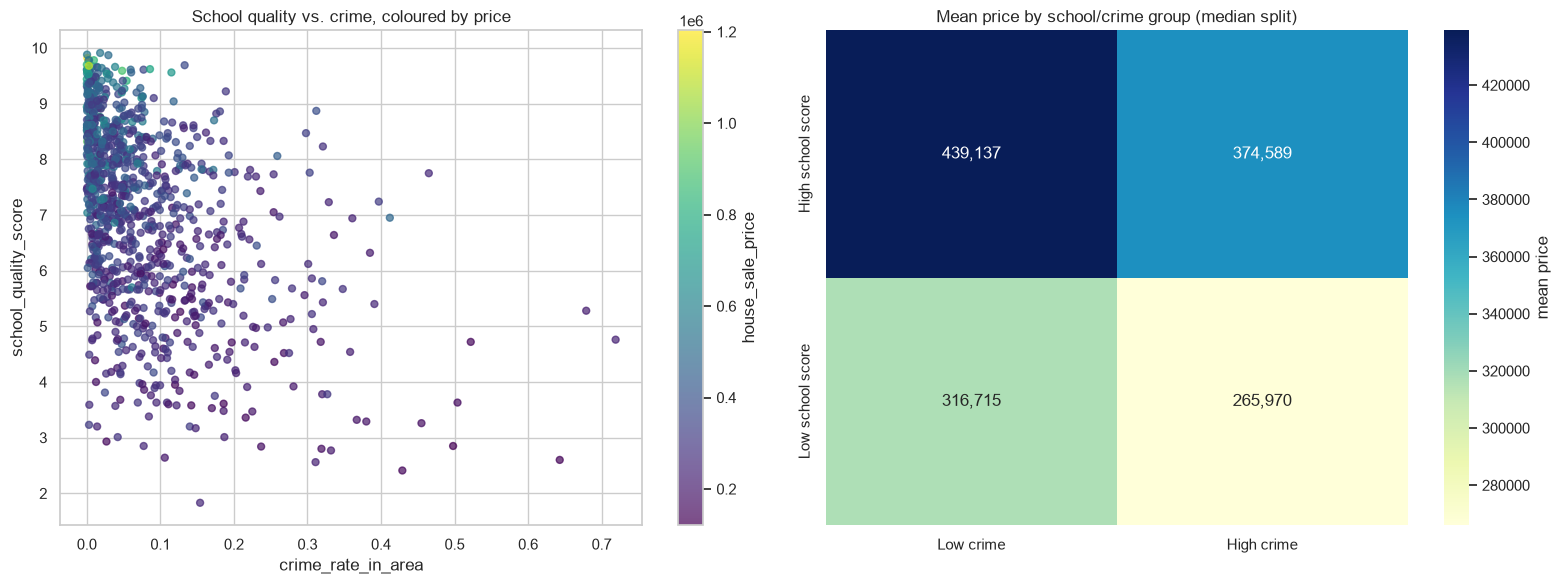

Group sizes:
_crime             High crime  Low crime
_school                                 
High school score         175        325
Low school score          325        175


In [52]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc = axes[0].scatter(df['crime_rate_in_area'], df['school_quality_score'],
                     c=df[target], cmap='viridis', alpha=0.7, s=25)
plt.colorbar(sc, ax=axes[0], label='house_sale_price')
axes[0].set_xlabel('crime_rate_in_area'); axes[0].set_ylabel('school_quality_score')
axes[0].set_title("School quality vs. crime, coloured by price")

# Median split into 2 x 2 groups
df['_school'] = np.where(df['school_quality_score'] >= df['school_quality_score'].median(), 'High school score', 'Low school score')
df['_crime'] = np.where(df['crime_rate_in_area'] <= df['crime_rate_in_area'].median(), 'Low crime', 'High crime')
pivot = df.pivot_table(index='_school', columns='_crime', values=target, aggfunc='mean')
pivot = pivot.loc[['High school score', 'Low school score'], ['Low crime', 'High crime']]
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlGnBu", ax=axes[1], cbar_kws={'label': 'mean price'})
axes[1].set_title("Mean price by school/crime group (median split)")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

counts = df.pivot_table(index='_school', columns='_crime', values=target, aggfunc='count')
print("Group sizes:"); print(counts)
df.drop(columns=['_school', '_crime'], inplace=True)

- Prices rise towards the high-school / low-crime corner and fall toward the low-school/high crime-corner. Mean prices in the 2x2 split are about 439k (high school, low crime), 375k (high school, high crime), 371k (low school, low crime) and 266k (low school, high crime).
- The effects look mostly additive. Moving from low to high school score adds about 122k when crime is low and about 109k when crime is high; moving from high to low crime adds about 64k when schools are good and about 51k when they are poor. The combined premium is only slightly larger than the sum of the parts, so there is at most a mild positive synergy.
- Caveat: the two features are correlated with each other (r about -0.44) and also with size and location, the group differences are not purely caused by schools and crime. Also, the groups are unbalanced (175 vs 325 rows in the off-diagonal cells), because of that correlations.

Modelling implication: a linear model with both features will capture most of this effect; a school x crime interaction term can be tried but I would expect a small gain. Tree-based models (random forest, gradient boosting) can pick up any remaining interaction automatically.

## 5.4 Extending the school and crime analysis: 3 x 3 tertile grid

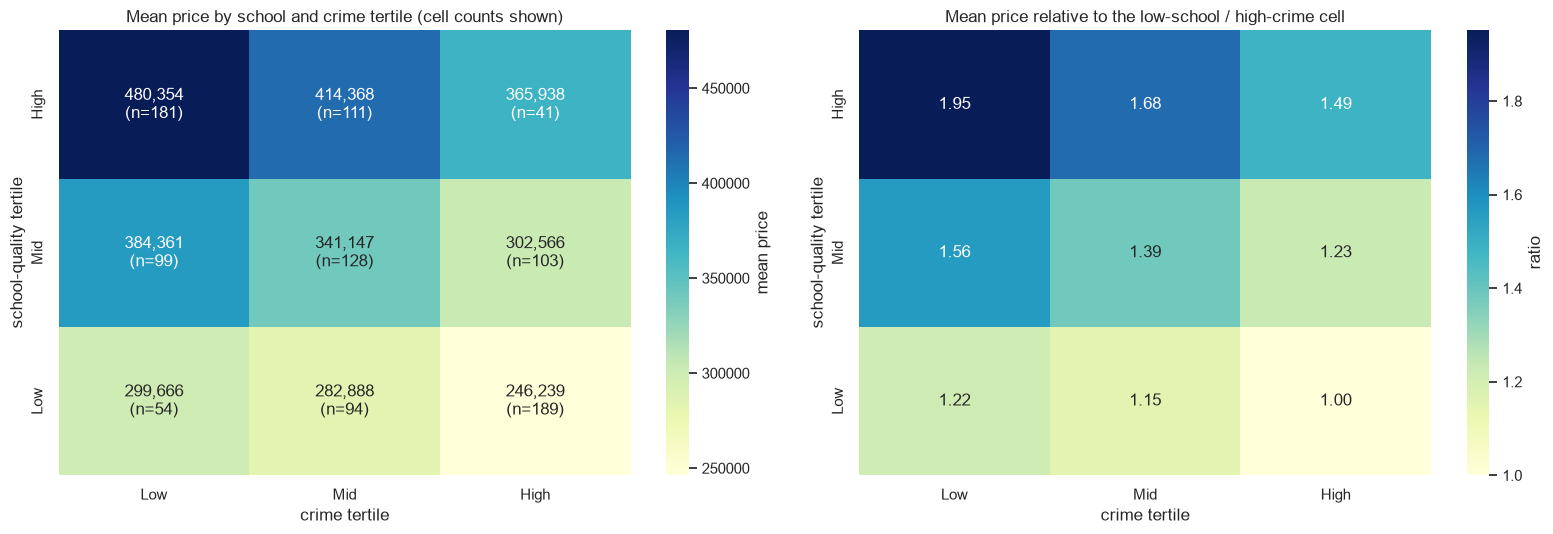

Price ratio, high vs low school tertile, within each crime tertile:
crime_tertile
Low     1.60
Mid     1.46
High    1.49

Price ratio, low vs high crime tertile, within each school tertile:
school_tertile
High    1.31
Mid     1.27
Low     1.22


In [53]:
levels = ['Low', 'Mid', 'High']
tmp = df.copy()
tmp['school_tertile'] = pd.qcut(tmp['school_quality_score'], 3, labels=levels)
tmp['crime_tertile'] = pd.qcut(tmp['crime_rate_in_area'], 3, labels=levels)

mean_p = tmp.pivot_table(index='school_tertile', columns='crime_tertile', values=target,
                         aggfunc='mean', observed=True).loc[levels[::-1], levels]
cnt = tmp.pivot_table(index='school_tertile', columns='crime_tertile', values=target,
                      aggfunc='count', observed=True).loc[levels[::-1], levels]
labels = np.array([[f"{mean_p.iloc[i, j]:,.0f}\n(n={cnt.iloc[i, j]})" for j in range(3)] for i in range(3)])
rel = mean_p / mean_p.loc['Low', 'High']          # relative to the cheapest cell (low school, high crime)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.heatmap(mean_p, annot=labels, fmt="", cmap="YlGnBu", ax=axes[0], cbar_kws={'label': 'mean price'})
axes[0].set_title("Mean price by school and crime tertile (cell counts shown)")
sns.heatmap(rel, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[1], cbar_kws={'label': 'ratio'})
axes[1].set_title("Mean price relative to the low-school / high-crime cell")
for ax in axes:
    ax.set_xlabel("crime tertile"); ax.set_ylabel("school-quality tertile")
plt.tight_layout()
plt.show()

print("Price ratio, high vs low school tertile, within each crime tertile:")
print((mean_p.loc['High'] / mean_p.loc['Low']).round(2).to_string())
print()
print("Price ratio, low vs high crime tertile, within each school tertile:")
print((mean_p['Low'] / mean_p['High']).round(2).to_string())

- **The pattern is steady across the whole range, not just at the extremes.** Price rise with school quality in every column and fall with crime in every row, with no plateau, from about 246k (low school, high crime) up to about 480k (high school, low crime).
- **Effects look multiplicative rather than additive.** In dollar terms the effects grow with the other factor: going from low to high school tertile adds about 181k when crime is low but about 120k when crime is high; going from high to low crime adds about 114k at high school quality but only about 53k at low school quality. As **ratios**, however, the effects are much more stable: the high-vs-low school premium is about 1.46x to 1.60x in every crime tertile, and the low-vs-high crime premium is about 1.22x to 1.31x in every school tertile. This refines the earlier 2 x 2 readingL the dollar differences suggested a mild synergy, but is largely just a consequence of percentage affects applied to different price levels. 
- **Cell counts:** the grid is unbalanced because school quality and crime are correlated. The two corners (high school / high crime, n=41; low school/low crime, n = 54) have fae fewer rows than the opposite corners (181 and 189), so the two cells are the least reliable.

**Modelling implication:** since effects are roughly multiplicative, a model on log(price) should treat school quality and crime as approximately additive, so an explicit school x crime interaction term is not needed for a log-target linear model. This is another point in favour of the log target. Tree-based models would capture any remaining interaction on their own.

# 6. Key Findings and Modelling Implications

**Data overview and quality**
- 1,000 rows, 8 predictors and 1 target; **no missing values and no duplicates**.
- `number_of_bedrooms` and `number_of_bathrooms` are **confirmed as standardised** (mean about 0, standard deviation about 1, 47.9% of bedroom values negative), so they are relative measures, not counts.
- `location_type` is imbalanced: Suburban 500, Urban 400, **Rural only 100**.

**Target**
- `house_sale_price` is **right-skewed** (skew about 1.57, excess kurtosis about 4.3) with 39 genuine-looking high-price outliers (3.9%). The Q-Q plot shows the problem is in the upper tail. log(price) fixes almost all of it (skew about 0.27); Box-Cox (lambda about -0.25) is slightly closer to normal still.

**Features**
- Strongest relationships with price: `property_size` (r about 0.71), bedrooms (0.65), `school_quality_score` (0.61), bathrooms (0.57); then crime (-0.40), transport proximity (0.30) and age (-0.28).
- **Crime:** the relationship is curved; `log(crime)` raises the correlation from -0.40 to -0.50 and removes the significant curvature.
- **Multicollinearity is mild:** the highest VIF is about 2.8 (bedrooms), and all are below 5, despite pairwise correlations of 0.60 to 0.73 among the size features.
- **Location:** the Kruskal-Wallis test is highly significant (p about 4e-11) but the effect is small (epsilon-squared about 0.046). Suburban homes are cheaper than both Rural and Urban; **Rural and Urban are not reliably different**.
- **Transport proximity:** positive within every location and robust to adjustment (about +1.2% price per unit), but its meaning needs confirming with the data owner.

**Interactions**
- Size-price slopes are broadly similar across locations, the crime effect is similar in every location, and school quality and crime act roughly **multiplicatively** (stable price ratios across a 3 x 3 grid), so they are close to additive on a log scale.

### 6.2 From EDA to modelling: decision table

| EDA finding | Risk / opportunity | Possible modelling action |
|---|---|---|
| Target right-skewed (skew 1.57; log 0.27; Box-Cox lambda about -0.25) | Large errors on expensive homes dominate RMSE; residual spread grows with price | Compare raw, log and Box-Cox targets; report MAE and a relative metric (MAPE or RMSLE) alongside RMSE |
| 39 high-price outliers (3.9%) that look genuine | Can pull an OLS fit toward the tail | Keep them; compare with a robust loss (e.g. Huber) and tree models; inspect influence diagnostics |
| Crime is curved against price; log lifts r from -0.40 to -0.50 | A raw-crime linear term under-uses this feature | Use `log(crime_rate_in_area)` in linear and regularised models; no change needed for trees |
| `property_size` (skew 2.0) and transport proximity (skew 1.5) are right-skewed | High-leverage points in linear models | Test log transforms of both for linear models |
| Size, bedrooms and bathrooms correlated (0.60 to 0.73), but VIF at most about 2.8 | Mild multicollinearity only | Plain OLS is acceptable; Ridge/Lasso is optional for tuning; check coefficient stability across CV folds |
| Location: small but significant effect; Suburban lower; Rural about equal to Urban; Rural n = 100 | Location matters modestly; the Rural group is small | One-hot encode; stratify splits and CV on `location_type`; consider whether Rural and Urban need separate levels |
| School quality and crime act multiplicatively (school premium about 1.5x to 1.6x in each crime tertile) | Additive on a log scale; little gain from an explicit interaction | Use a log target; treat an interaction term as optional; compare with gradient boosting / random forest |
| Transport proximity positive in all locations (about +1.2% per unit), counterintuitive for a distance | Unclear definition; risk of causal over-interpretation | Keep as is; confirm the definition with the data owner; avoid causal wording in reports |
| Bedrooms and bathrooms are z-scores | Not interpretable as counts | Do not round or clip; they need no further scaling, but the other features do for linear or distance-based models |
| No missing values or duplicates | No cleaning required | No imputation or de-duplication step needed |

**Suggested next steps:** train/test split stratified by `location_type`; baseline linear models on raw and log targets (with `log(crime)`); regularised and tree-based models; compare by cross-validated RMSE, MAE and a relative-error metric; inspect residual plots for heteroscedasticity.

Target
- house_sale_price is right-skewed (skey about 1.57), with 39 high-price outliers (3.9%) that look genuine. A log transform brings skew down to 0.27.
- report MAE and a relative-error metric alongside RMSE and test a log-target model.

Features
- Strongest predictors: property_size (r about 0.71), bedrooms (0.65), school_quality_score (0.61), bathrooms (0.57); then crime (-0.40), transport proximity (0.30), age (-0.28).
- Heavy right skew in crime_rate_in_area, property_size and proximity_to_public_transport: condider log transforms for linear models.
- Size, bedrooms and bathrooms are inter-correlated (0.60.to 0.73): check VIF (Variance Inflation Factor); prefer regularisation (Ridge/Lasso) or tree ensembles over plain Ordinary Least Squares.
- Rural homes are the most expensive on average, diven by lower crime and better schools there, so location_type should be one-hot encoded, with stratified CV.

Interactions
- Size-price slopes are similar across locations (location mostly shifts the price level), the crime effect is similarly negative in every locationm and the school x crime combination is close to additive with at most a mild synergy.
- Explicit interaction terms are optional for linear models; gradient boosting / random forest are good candidates to compare against a regularised linear baseline.
